# Step 4: shape table + PCA

1. **Shape table:** the trials are chosen (settings), each cut movement (step 3) is stretched to `N_POINTS` points evenly spaced in time, and each trial becomes **one row**: info columns, `start_delay_s`, `movement_duration_s`, then the shape (`wrist_forward_000 ... wrist_up_199`). `start_delay_s` and `movement_duration_s` are kept apart: they do not go into the PCA.
2. **One PCA per task** on the shape columns.

Input: `movement_cut.parquet` and `movement_cut_trials.parquet` (step 3), `trials`, `sessions`, `kinematics_trials` (steps 1-2), and the 2 hand-filled files `data/session_participant.csv` (who each session is, which visit) and `data/participants.csv` (condition). Code: `shapes.py` and `pca.py`.

In [28]:
%load_ext autoreload
%autoreload 2
import pandas as pd

import pca
import shapes
from config import OLD_PROCESSED_ROOT

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Settings
Change a value, then re-run from here. They are saved next to the output (`shapes_settings.json`).

In [29]:
INCLUDE_NO_ID = True          # sessions without a patient ID (healthy participants)
INCLUDE_TESTS = True          # test sessions
ONLY_PASSING_TRIALS = True    # keep only trials with passes_checks
SKIP_FIRST_REPETITION = True  # leave out repetition 1 (practice trial)
N_POINTS = 200                # points per movement after stretching
POINTS = ["wrist"]            # body points in the shape: ["wrist"] or ["wrist", "elbow"]
SCALE_BY_ARM_LENGTH = False   # True = positions divided by the arm length
SHAPE_PART = "whole"          # "whole" = the movement out and back (as cut in step 3),
                              # "way_out" = from the movement start to the goal (goal_time, step 1)
N_KEEP = 10                   # PCA components saved per trial
N_PCS_SHOWN = 3               # components drawn in the plots

In [30]:
# The settings collected for the functions.
settings = {"include_no_id": INCLUDE_NO_ID, "include_tests": INCLUDE_TESTS, "only_passing_trials": ONLY_PASSING_TRIALS,
            "skip_first_repetition": SKIP_FIRST_REPETITION, "n_points": N_POINTS, "points": POINTS,
            "scale_by_arm_length": SCALE_BY_ARM_LENGTH, "shape_part": SHAPE_PART, "n_keep": N_KEEP,
            "n_pcs_shown": N_PCS_SHOWN}
UNIT = "arm lengths" if SCALE_BY_ARM_LENGTH else "m"

movement_cut, cut_trials, trials, sessions, kinematics_trials = shapes.load_inputs()
print(f"Shape used here: {' + '.join(POINTS)}, {N_POINTS} points, in {UNIT}, SHAPE_PART = {SHAPE_PART!r}")

Shape used here: wrist, 200 points, in m, SHAPE_PART = 'whole'


## 1. Build the shape table

- **Person:** `participant_id` when it is filled in (`session_participant.csv`), otherwise `noid_<date>_<time>`.
- **Condition:** from `participants.csv`: `healthy`, the diagnosis (`Stroke`, `CBD`, `PSP`, ...), or `unknown`. Sessions without an ID are healthy (only the clinical team's patients are patients).
- **Visit:** 1 = first assessment, 2 = reassessment (`session_participant.csv`).
- **Trials:** those kept by step 3, then the 4 switches in this order: `INCLUDE_NO_ID`, `INCLUDE_TESTS` (test = participant_id starting with "test"), `ONLY_PASSING_TRIALS`, `SKIP_FIRST_REPETITION`.
- **Stretching:** each movement to `N_POINTS` points evenly spaced in time (`np.interp`). The first and last positions are kept. Frames with a missing position are left out first (a long gap is then bridged by the stretching, as in the old code).
- `SHAPE_PART = "way_out"`: only from the movement start to the goal; trials without a goal time are then left out.

⚠️ The first visits of DBB, MAM and JFR (no ID typed), MBM → MAM and 004 → JFR are assigned by hand in `session_participant.csv`, **to be confirmed by Luana** (JFR's first visit is UNSURE: see the notes in the file).

In [31]:
people = shapes.session_people(sessions)
info = shapes.trial_info(trials, people, kinematics_trials, cut_trials)
selected, stages = shapes.select_trials(info, settings)
shape_table = shapes.build_shape_table(movement_cut, selected, settings)

print(f"Shape table: {len(shape_table)} trials x {shape_table.shape[1]} columns")
shape_table.head()

Shape table: 2525 trials x 614 columns


,trial_id,session_id,task_id,task_name,person,condition,visit,side,target,task_run,trial_index,facing_ok,start_delay_s,movement_duration_s,wrist_forward_000,...,wrist_up_185,wrist_up_186,wrist_up_187,wrist_up_188,wrist_up_189,wrist_up_190,wrist_up_191,wrist_up_192,wrist_up_193,wrist_up_194,wrist_up_195,wrist_up_196,wrist_up_197,wrist_up_198,wrist_up_199
0,upper_limb_20260629_090253_002,upper_limb_20260629_090253,1,Shoulder flexion with elbow extended,noid_20260629_090253,healthy,<NA>,right,90,1,2,True,0.282721,1.104012,0.070579,...,-0.216254,-0.225517,-0.234779,-0.244042,-0.253305,-0.262981,-0.273112,-0.283243,-0.293375,-0.303506,-0.313637,-0.323768,-0.333899,-0.344031,-0.354162
1,upper_limb_20260629_090253_003,upper_limb_20260629_090253,1,Shoulder flexion with elbow extended,noid_20260629_090253,healthy,<NA>,right,90,1,3,True,0.051801,1.267957,0.136677,...,-0.118626,-0.128186,-0.137746,-0.147306,-0.156867,-0.166427,-0.175904,-0.185179,-0.194455,-0.203730,-0.213006,-0.222281,-0.231557,-0.240833,-0.250108
2,upper_limb_20260629_090253_004,upper_limb_20260629_090253,1,Shoulder flexion with elbow extended,noid_20260629_090253,healthy,<NA>,right,90,1,4,True,0.001485,1.394365,0.290372,...,-0.083290,-0.092778,-0.102265,-0.111753,-0.121240,-0.130728,-0.140215,-0.150064,-0.160528,-0.170993,-0.181457,-0.191921,-0.202385,-0.212850,-0.223314
3,upper_limb_20260629_090253_005,upper_limb_20260629_090253,1,Shoulder flexion with elbow extended,noid_20260629_090253,healthy,<NA>,right,90,1,5,True,0.002467,1.295734,0.313159,...,-0.002661,-0.008718,-0.014775,-0.020832,-0.026889,-0.032946,-0.039796,-0.048572,-0.057348,-0.066124,-0.074900,-0.083676,-0.092451,-0.101227,-0.110003
4,upper_limb_20260629_090253_006,upper_limb_20260629_090253,1,Shoulder flexion with elbow extended,noid_20260629_090253,healthy,<NA>,right,90,1,6,True,0.000211,1.239985,0.386524,...,-0.032769,-0.040037,-0.047305,-0.054572,-0.061840,-0.069108,-0.077026,-0.085292,-0.093558,-0.101824,-0.110089,-0.118355,-0.126621,-0.134886,-0.143152


### Which sessions and trials are left after each stage (named / no ID / test)

Why 29 usable sessions and not 79 like the old notebook text: the 79 came from older settings of the old preprocessing (at least **1** repetition of one task, people standing kept). The old tables that the old PCA used already had these same 29 sessions: at least **4** repetitions of one task with one arm (`MIN_TRIALS_ONE_TASK`), and people standing removed (`MAX_HEAD_HEIGHT_M`: staff testing the setup). Going from 79 to 29 loses 50 sessions but only 210 trials (3,013 → 2,803): mostly quick recording tests with 1-3 trials, and all 20 test sessions (staff standing).

In [32]:
shapes.selection_table(people, info, stages, shape_table)

sessions                  trials                 
                                        named no ID test total  named no ID test total
step 1: all recorded sessions              19    72   21   112   2442   506   65  3013
step 1: usable sessions                    14    15    0    29   2437   366    0  2803
step 2: kinematics computed                14    15    0    29   2425   363    0  2788
step 3: clear movement (cut)               14    15    0    29   2402   362    0  2764
step 4: INCLUDE_NO_ID = True               14    15    0    29   2402   362    0  2764
step 4: INCLUDE_TESTS = True               14    15    0    29   2402   362    0  2764
step 4: ONLY_PASSING_TRIALS = True         14    15    0    29   2346   349    0  2695
step 4: SKIP_FIRST_REPETITION = True       14    15    0    29   2200   325    0  2525
step 4: in the shape table                 14    15    0    29   2200   325    0  2525

In [33]:
# Per task: how many trials each switch left out, then trials and persons in the table.
shapes.per_task_table(info, stages, shape_table)

,,after step 3,left out by INCLUDE_NO_ID,left out by INCLUDE_TESTS,left out by ONLY_PASSING_TRIALS,left out by SKIP_FIRST_REPETITION,left out: no frames left,trials,persons
task_id,task_name,,,,,,,,
1,Shoulder flexion with elbow extended,304,0,0,4,24,0,276,13
2,Shoulder abduction with elbow extended,278,0,0,6,24,0,248,10
3,Draw a 5 segment trajectory,216,0,0,10,20,0,186,9
4,Reaching different targets,528,0,0,5,18,0,505,8
5,Draw a circle,214,0,0,14,16,0,184,9
6,Horizontal reaching,720,0,0,11,27,0,682,16
7,Drinking test: reaching glass to mouth,261,0,0,15,20,0,226,9
8,Index to nose,243,0,0,4,21,0,218,8


### Check: one trial, cut movement vs stretched points
The orange points must sit on the blue line: stretching must not change the movement. Choose any `trial_id` of the shape table.

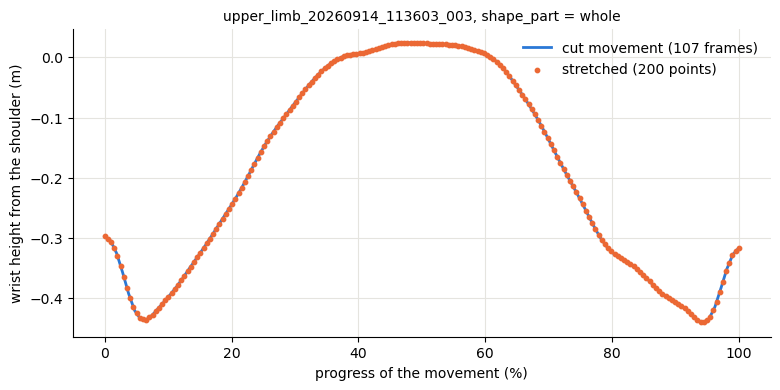

In [34]:
CHECK_TRIAL = "upper_limb_20260914_113603_003"   # task 1 (arm raised forward), repetition 3

shapes.plot_stretch_check(movement_cut, shape_table, info, CHECK_TRIAL, settings)

## 2. One PCA per task

**What a PCA does:** every trial is a long list of numbers (e.g. 600). The PCA finds the few main ways in which trials differ (the "components"): PC1 = the biggest difference, PC2 = the next one, ... Each trial is then described by a few numbers (its amount of each component). A PCA does **not** know about the diagnosis: it finds the biggest differences.

Tasks 4 and 6 (several targets): before the PCA, each trial minus the average movement for the same target and arm (+ the overall average), so the PCA compares people, not targets.

**Per task, 3 plots:**
1. **What each component explains:** bars = share of the differences per component, line = running total.
2. **What each component means:** grey = average movement, blue = average + the component, orange = average − the component. The difference blue vs orange = what the component changes.
3. **Map of the trials:** each dot = one trial. **Colour = condition** (healthy in black, unknown in grey), **marker = person** (the same in every task, so the 2 visits of a patient have the same marker).

**Check one person** (cell under each task): a person (`person` column; if the person came twice, the last visit is used), an arm and a repetition (the real repetition number: 1 = first of the task, usually not in the table). Left: the map, this person's trials in colour, the chosen repetition circled. Right: this repetition (black), the person's other repetitions (thin) and the task average (grey dotted).

In [35]:
STYLES = pca.plot_styles(shape_table)   # colour = condition, marker = person, fixed for every task
print("Not healthy:", ", ".join(label for _, _, label in STYLES.values()))

Not healthy: MAM (CBD), MFC (MSA-C), JFR (PSP), LSR (Parkinson), FCG (SCA3), DBB (Stroke), ISA (Stroke)


## Task 1: Shoulder flexion with elbow extended

Task 1 (Shoulder flexion with elbow extended): 276 trials from 13 persons (CBD: 1, MSA-C: 1, PSP: 1, Parkinson: 1, SCA3: 1, Stroke: 2, healthy: 6), 200 points x 3 directions x 1 point(s) (wrist)


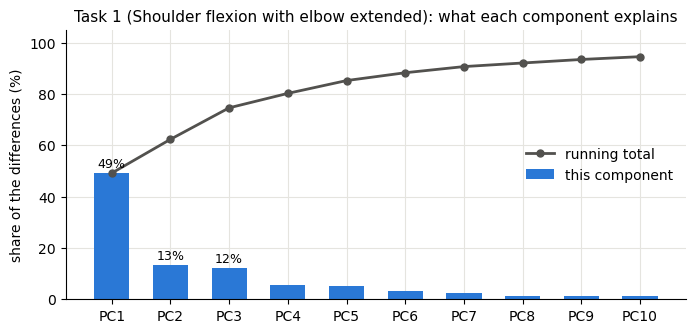

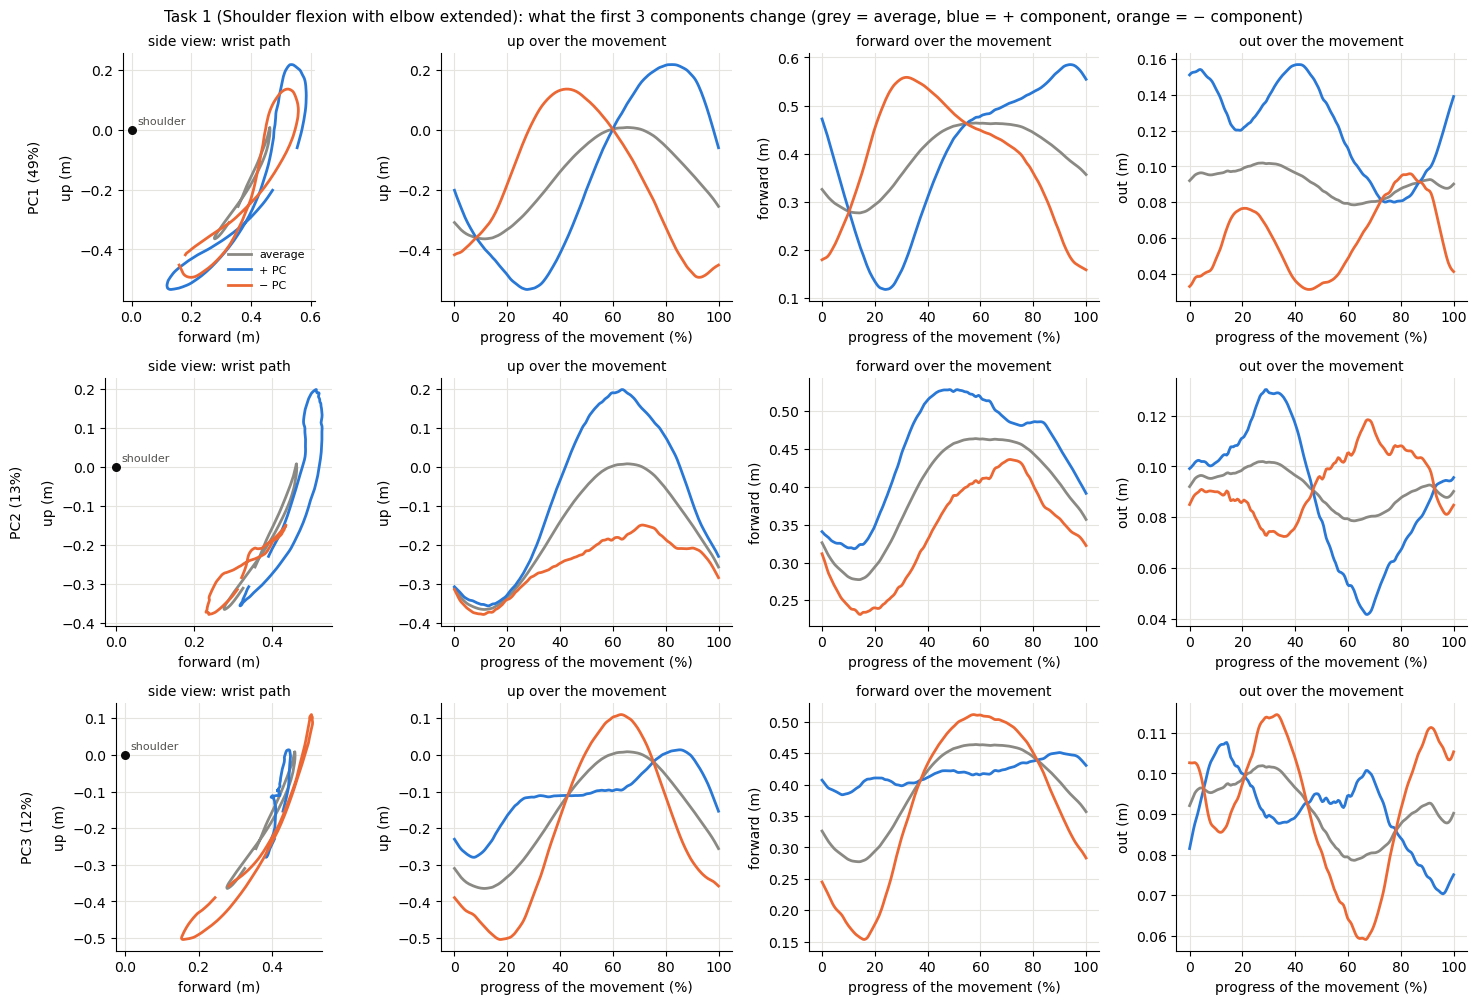

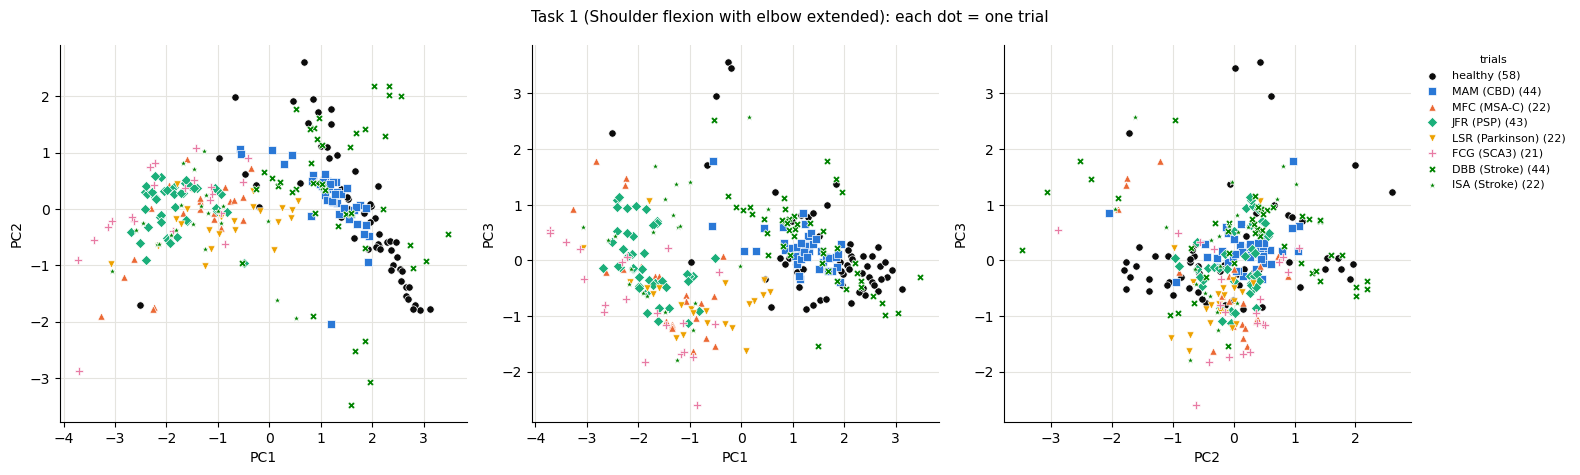

{'task_id': 1,
 'trials': 276,
 'persons': 13,
 'PC1_%': np.float64(49.1),
 'PC2_%': np.float64(13.2),
 'PC3_%': np.float64(12.3),
 'PC1-3_total_%': np.float64(74.6)}

In [36]:
pca.run_task(shape_table, 1, STYLES, N_KEEP, N_PCS_SHOWN, UNIT)

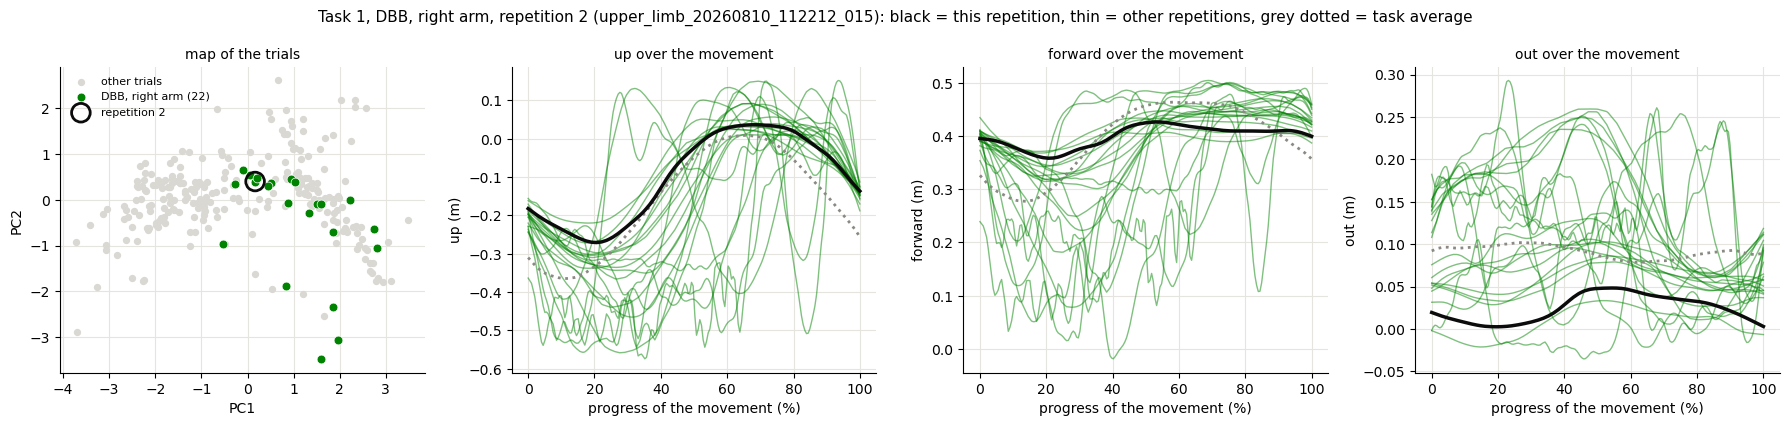

     this repetition  DBB median  DBB spread (std)  all trials spread (std)
PC1             0.16        0.99              0.95                     1.72
PC2             0.40       -0.08              1.20                     0.89
PC3             0.96        0.67              0.86                     0.86


In [37]:
pca.inspect_trial(shape_table, 1, person="DBB", side="right", repetition=2, styles=STYLES, pcs=("PC1", "PC2"), unit=UNIT)

### What PC1 means now in task 1 (with `SHAPE_PART = "whole"`)
In the old code, PC1 was mostly the waiting time before moving. That is gone: step 3 cuts the waiting away.

Now PC1 is **how the trial was ended**:
- **+ PC1 (blue):** the wrist first goes *down* (the arm is still coming back from the previous trial), reaches the top late, and the trial stops before the arm is back down = **automatic end** (mostly before 02/09).
- **− PC1 (orange):** starts at rest, reaches the top early, comes all the way back = **ended by the operator** (from 02/09).

92% of the auto-end trials have PC1 > 0, against 6% of the operator-ended ones (task 2: 81% vs 5%). Most patients were recorded after 02/09, so with `"whole"` PC1 separates the recording period, not the persons. With `SHAPE_PART = "way_out"` this mostly disappears (task 1: 35% vs 63%, task 2: 40% vs 47%).

## Task 2: Shoulder abduction with elbow extended

Task 2 (Shoulder abduction with elbow extended): 248 trials from 10 persons (CBD: 1, MSA-C: 1, PSP: 1, Parkinson: 1, SCA3: 1, Stroke: 2, healthy: 3), 200 points x 3 directions x 1 point(s) (wrist)


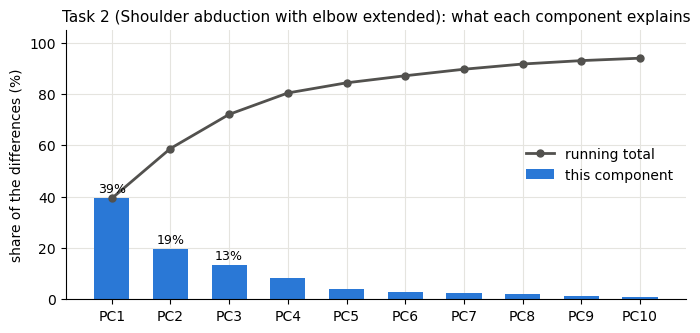

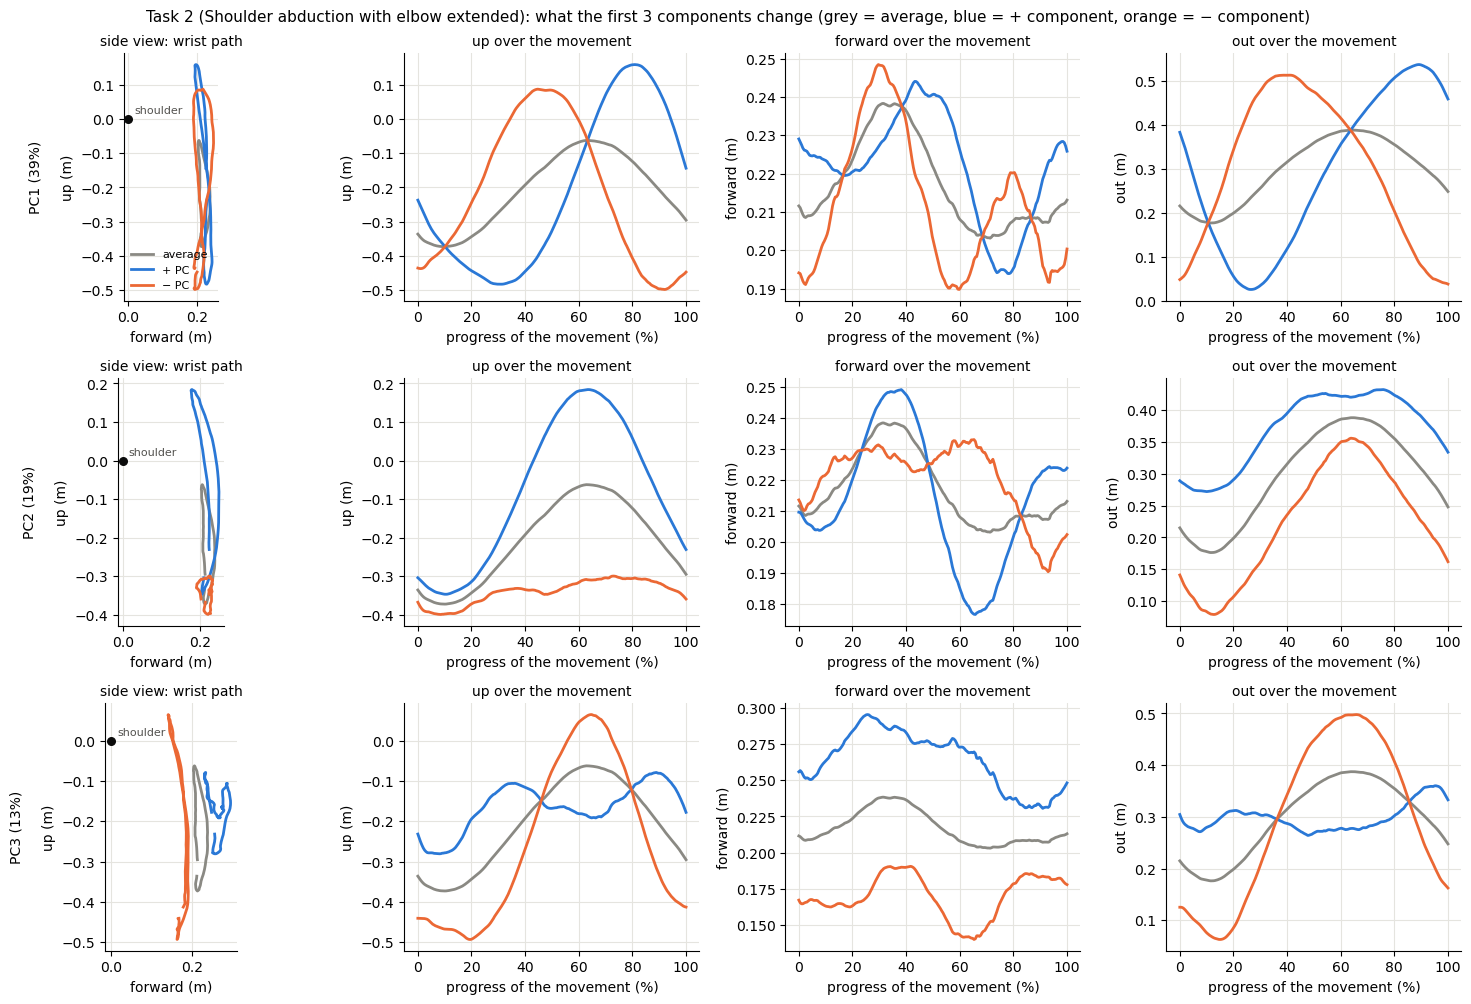

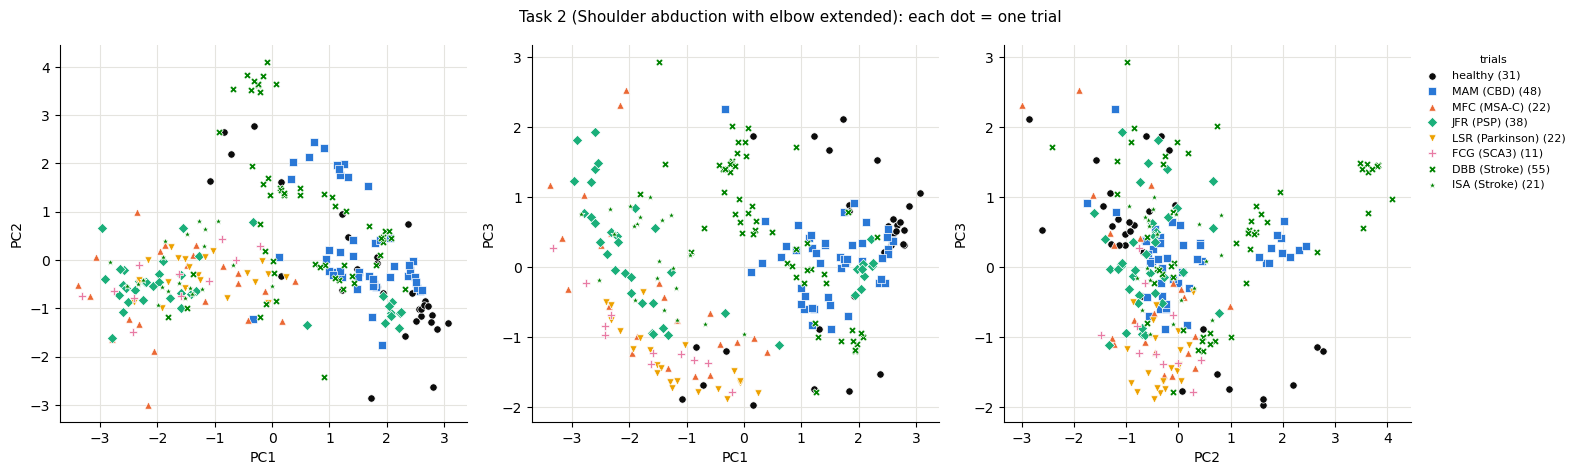

{'task_id': 2,
 'trials': 248,
 'persons': 10,
 'PC1_%': np.float64(39.3),
 'PC2_%': np.float64(19.5),
 'PC3_%': np.float64(13.3),
 'PC1-3_total_%': np.float64(72.0)}

In [38]:
pca.run_task(shape_table, 2, STYLES, N_KEEP, N_PCS_SHOWN, UNIT)

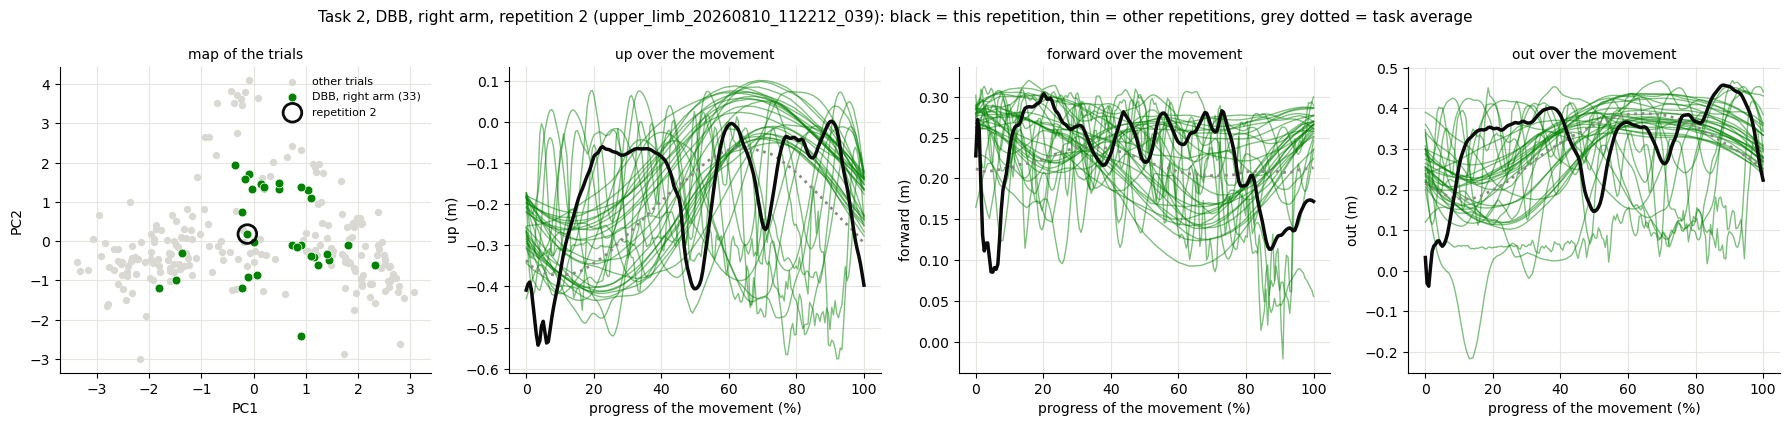

     this repetition  DBB median  DBB spread (std)  all trials spread (std)
PC1            -0.12        0.21              0.90                     1.74
PC2             0.18       -0.09              1.10                     1.22
PC3             1.63        0.52              0.83                     1.01


In [39]:
pca.inspect_trial(shape_table, 2, person="DBB", side="right", repetition=2, styles=STYLES, pcs=("PC1", "PC2"), unit=UNIT)

## Task 3: Draw a 5 segment trajectory

Task 3 (Draw a 5 segment trajectory): 186 trials from 9 persons (CBD: 1, PSP: 1, Parkinson: 1, SCA3: 1, Stroke: 1, healthy: 4), 200 points x 3 directions x 1 point(s) (wrist)


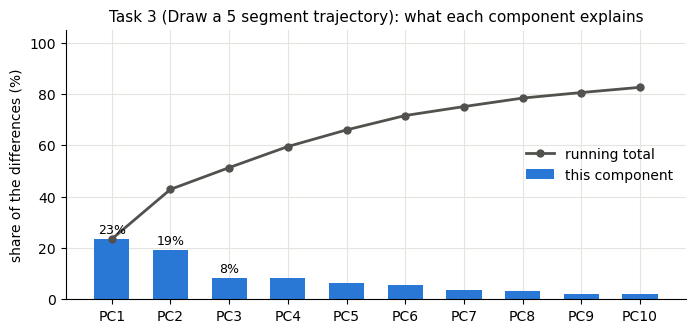

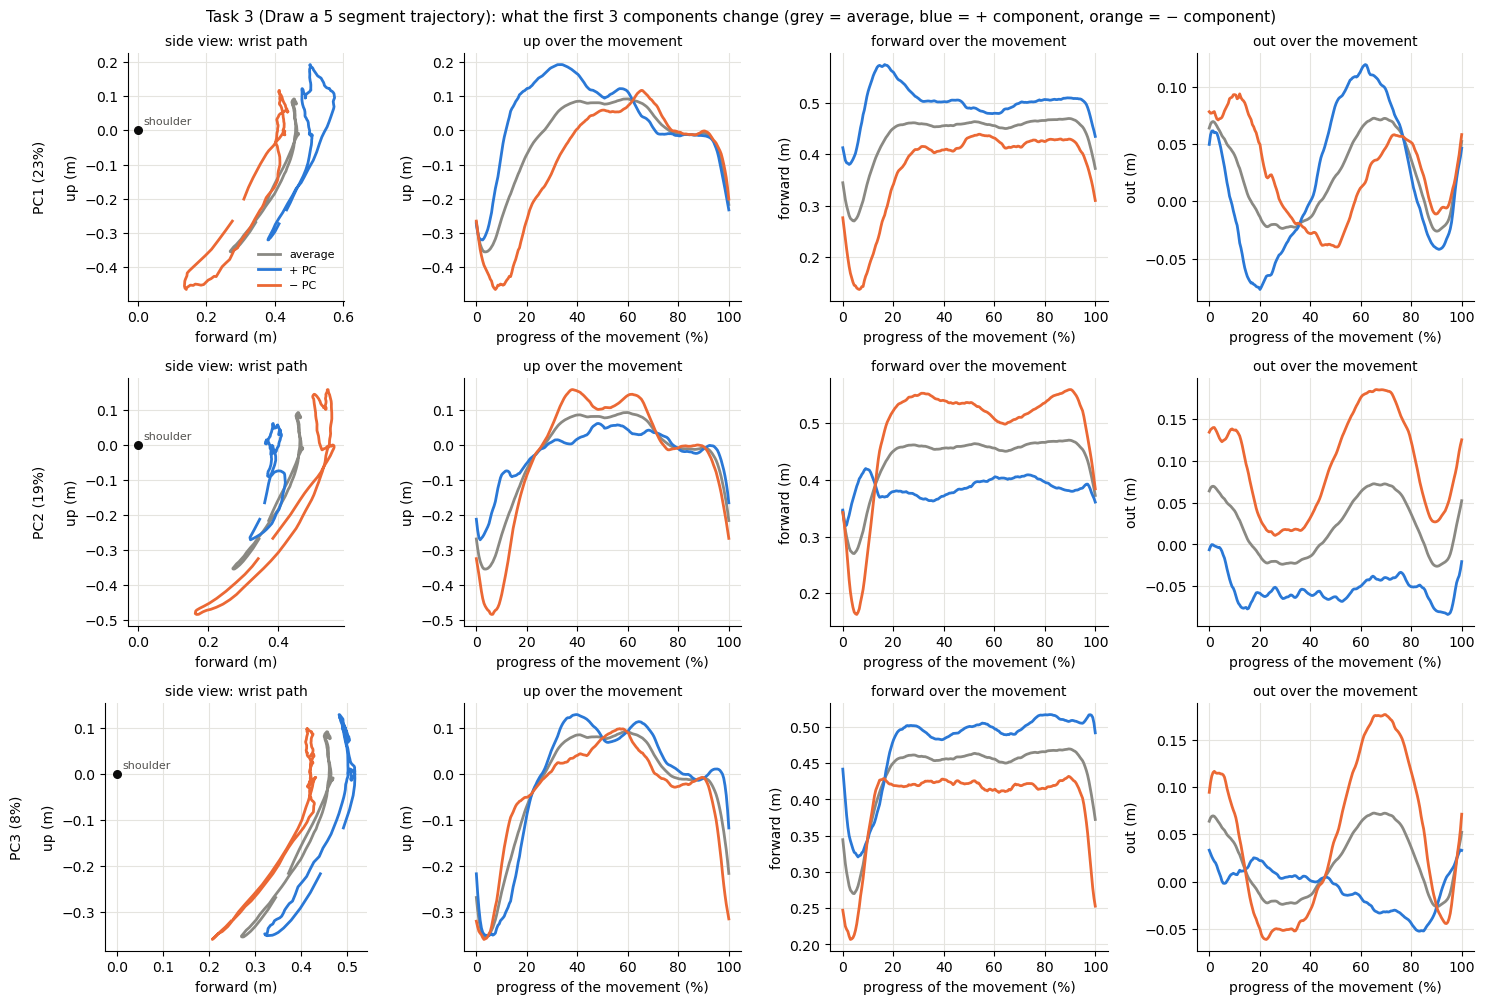

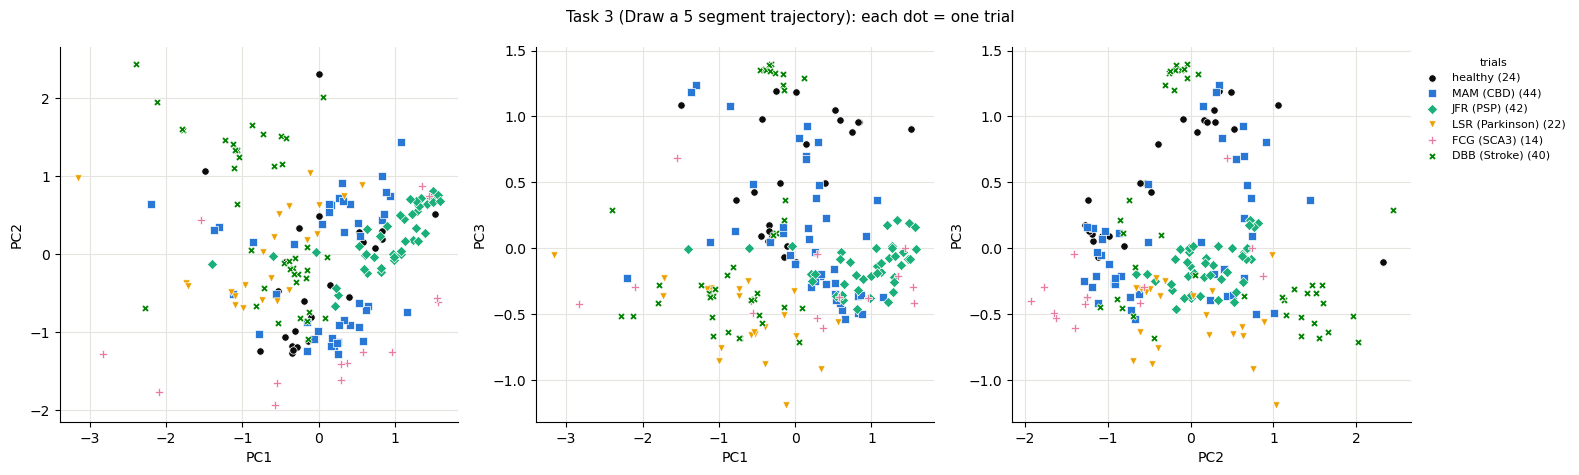

{'task_id': 3,
 'trials': 186,
 'persons': 9,
 'PC1_%': np.float64(23.4),
 'PC2_%': np.float64(19.4),
 'PC3_%': np.float64(8.5),
 'PC1-3_total_%': np.float64(51.3)}

In [40]:
pca.run_task(shape_table, 3, STYLES, N_KEEP, N_PCS_SHOWN, UNIT)

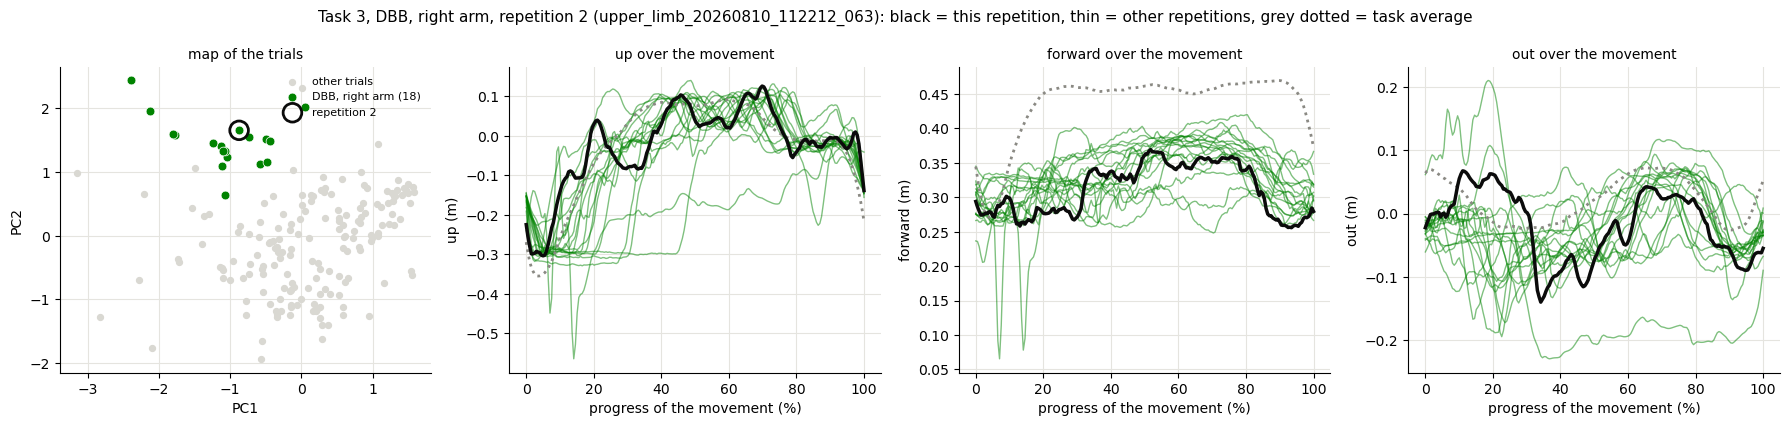

     this repetition  DBB median  DBB spread (std)  all trials spread (std)
PC1            -0.88       -1.07              0.63                     0.95
PC2             1.66        1.47              0.40                     0.86
PC3            -0.64       -0.41              0.23                     0.57


In [41]:
pca.inspect_trial(shape_table, 3, person="DBB", side="right", repetition=2, styles=STYLES, pcs=("PC1", "PC2"), unit=UNIT)

## Task 4: Reaching different targets

Task 4 (Reaching different targets): 505 trials from 8 persons (CBD: 1, PSP: 1, Parkinson: 1, SCA3: 1, Stroke: 1, healthy: 3), 200 points x 3 directions x 1 point(s) (wrist)


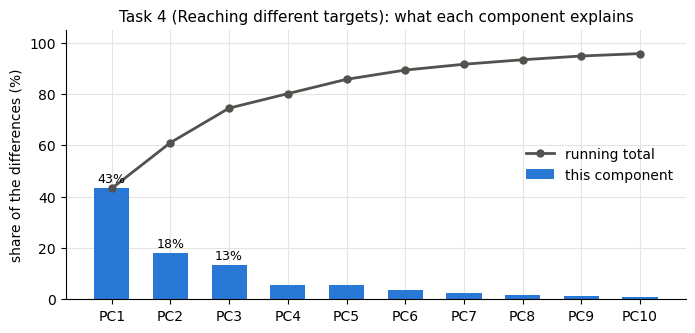

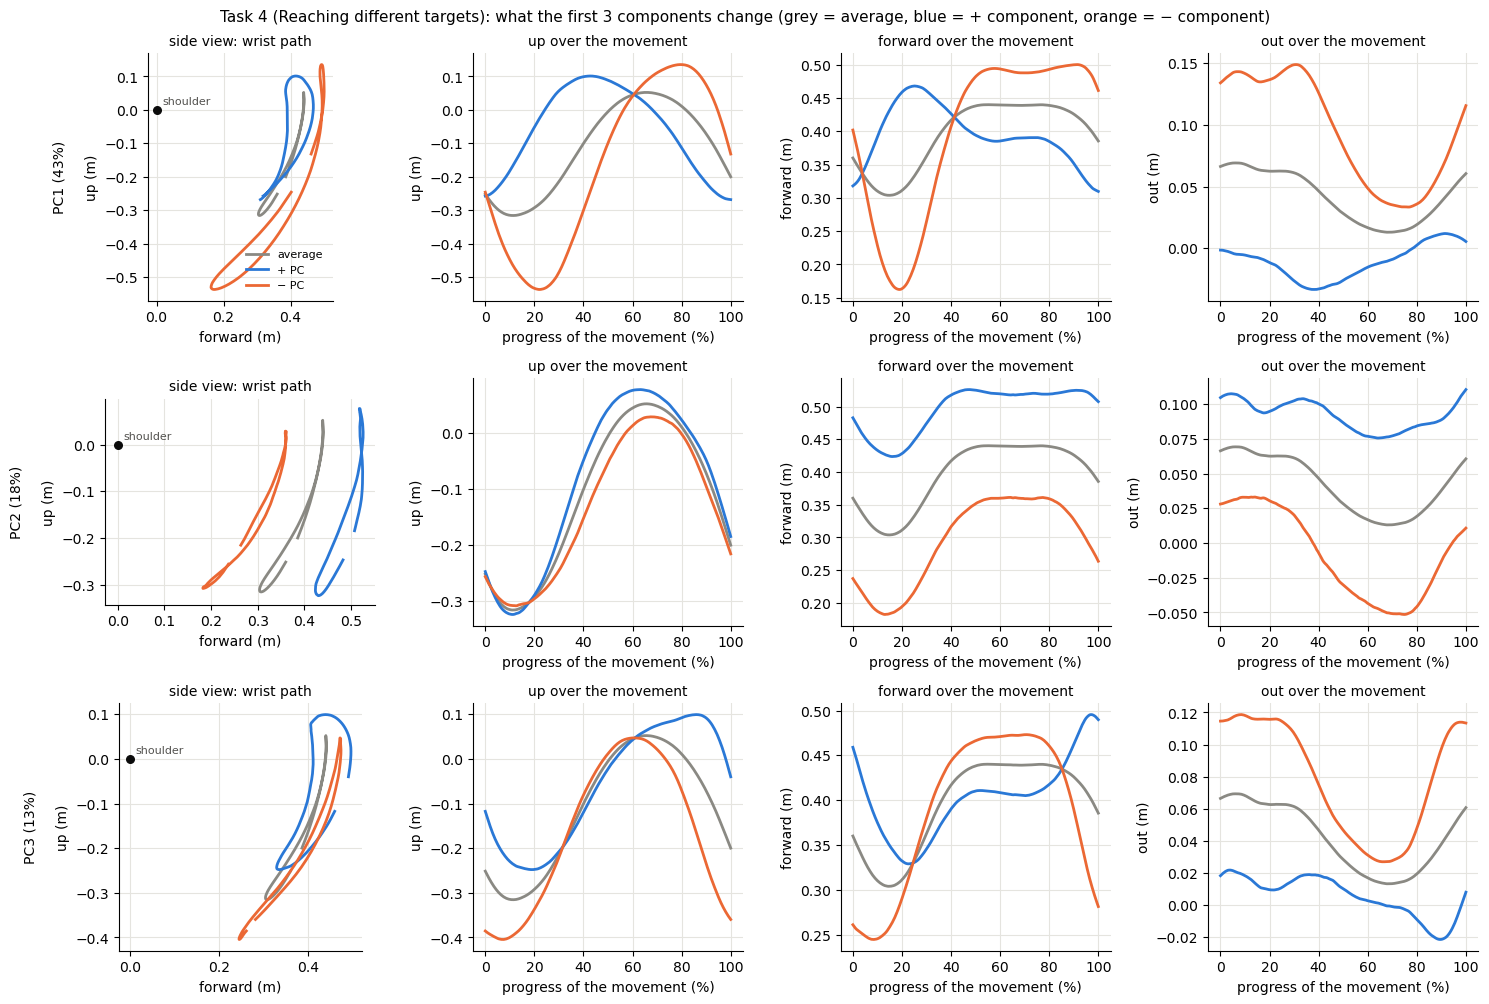

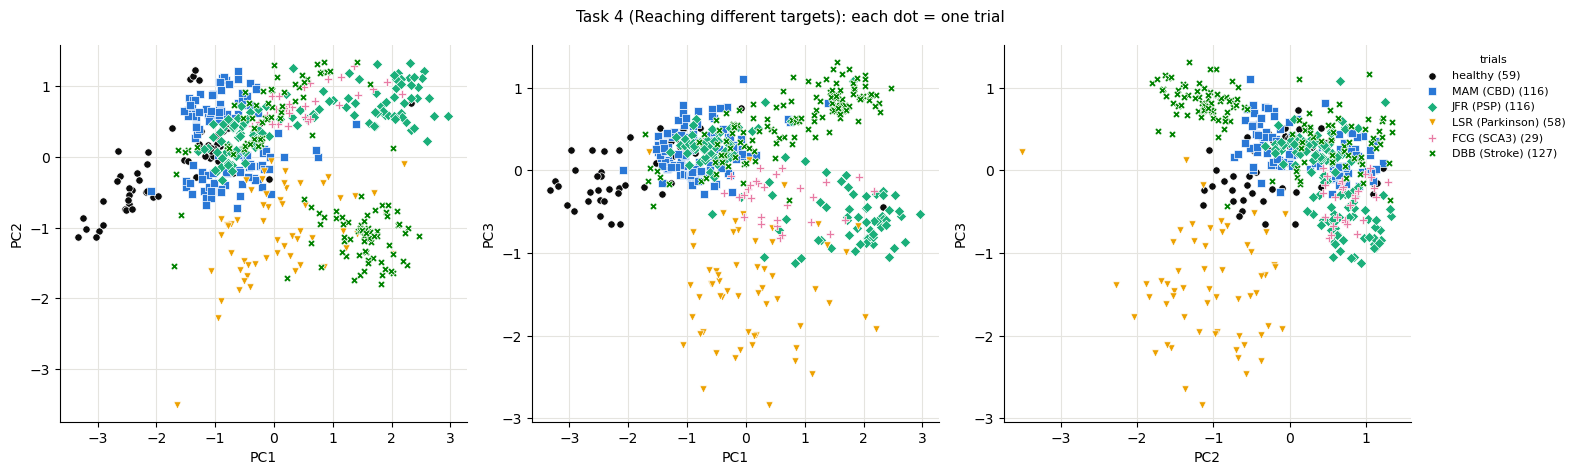

{'task_id': 4,
 'trials': 505,
 'persons': 8,
 'PC1_%': np.float64(43.2),
 'PC2_%': np.float64(17.9),
 'PC3_%': np.float64(13.4),
 'PC1-3_total_%': np.float64(74.5)}

In [42]:
pca.run_task(shape_table, 4, STYLES, N_KEEP, N_PCS_SHOWN, UNIT)

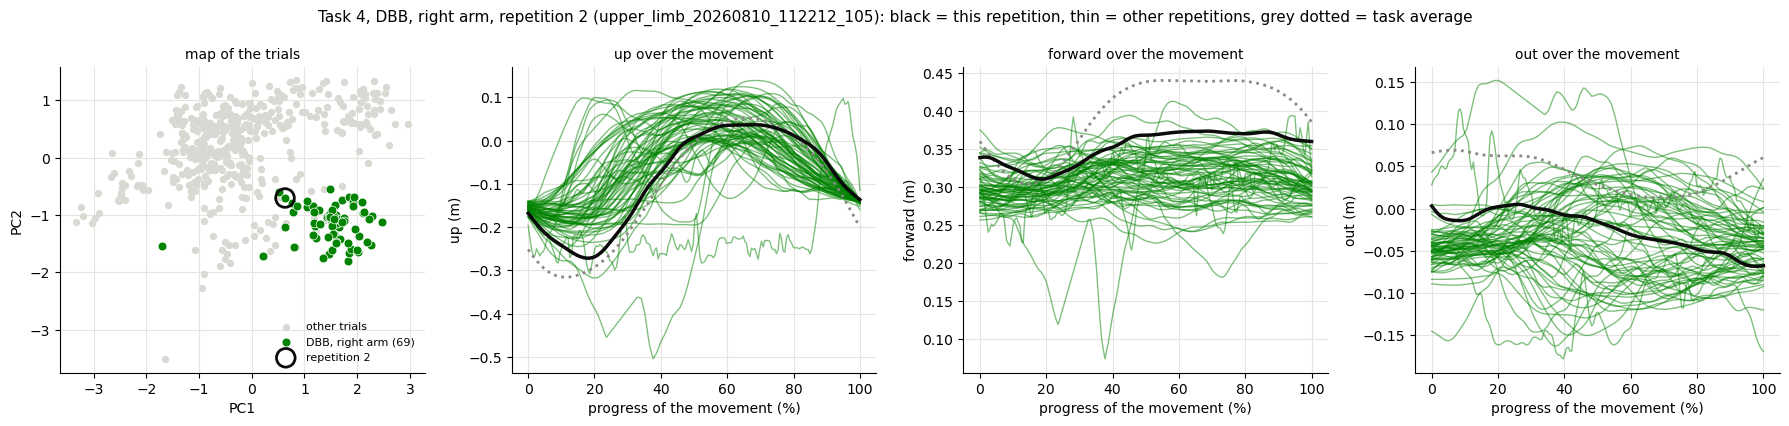

     this repetition  DBB median  DBB spread (std)  all trials spread (std)
PC1             0.63        1.56              0.60                     1.29
PC2            -0.70       -1.12              0.31                     0.83
PC3             0.80        0.84              0.19                     0.72


In [43]:
pca.inspect_trial(shape_table, 4, person="DBB", side="right", repetition=2, styles=STYLES, pcs=("PC1", "PC2"), unit=UNIT)

## Task 5: Draw a circle

Task 5 (Draw a circle): 184 trials from 9 persons (CBD: 1, PSP: 1, Parkinson: 1, SCA3: 1, Stroke: 1, healthy: 4), 200 points x 3 directions x 1 point(s) (wrist)


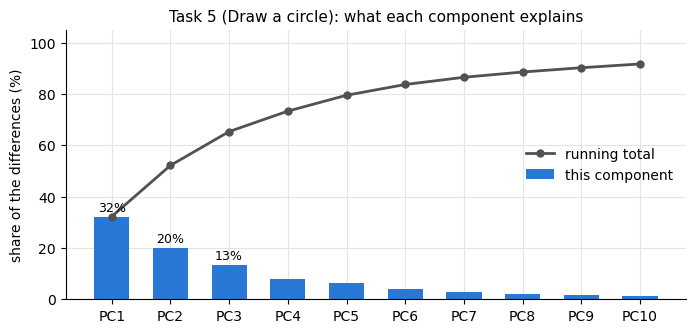

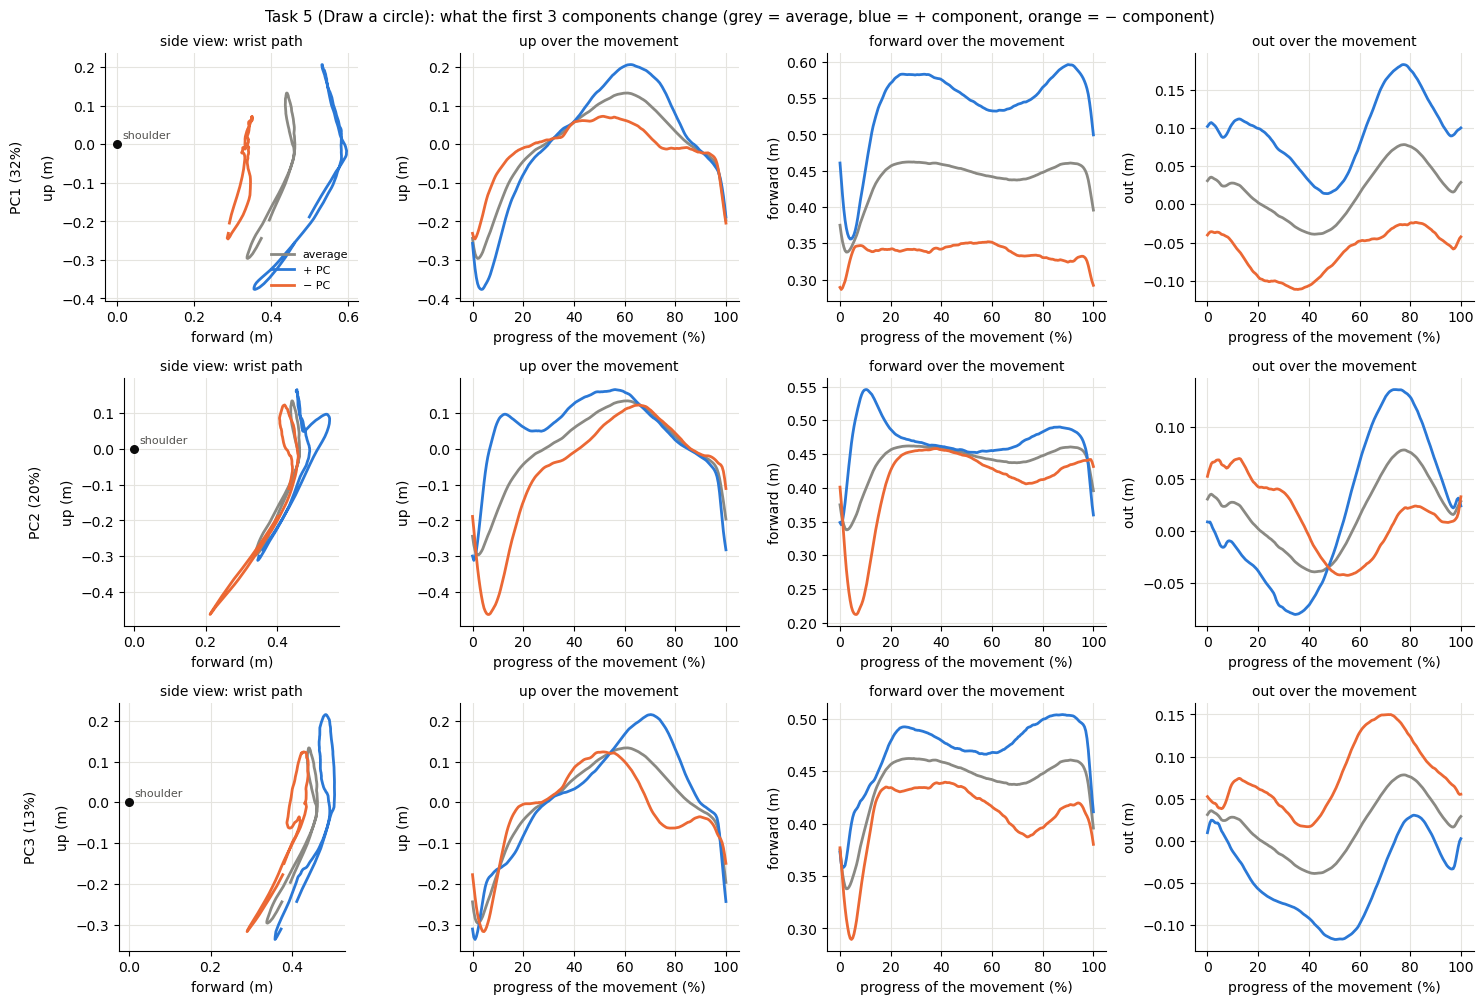

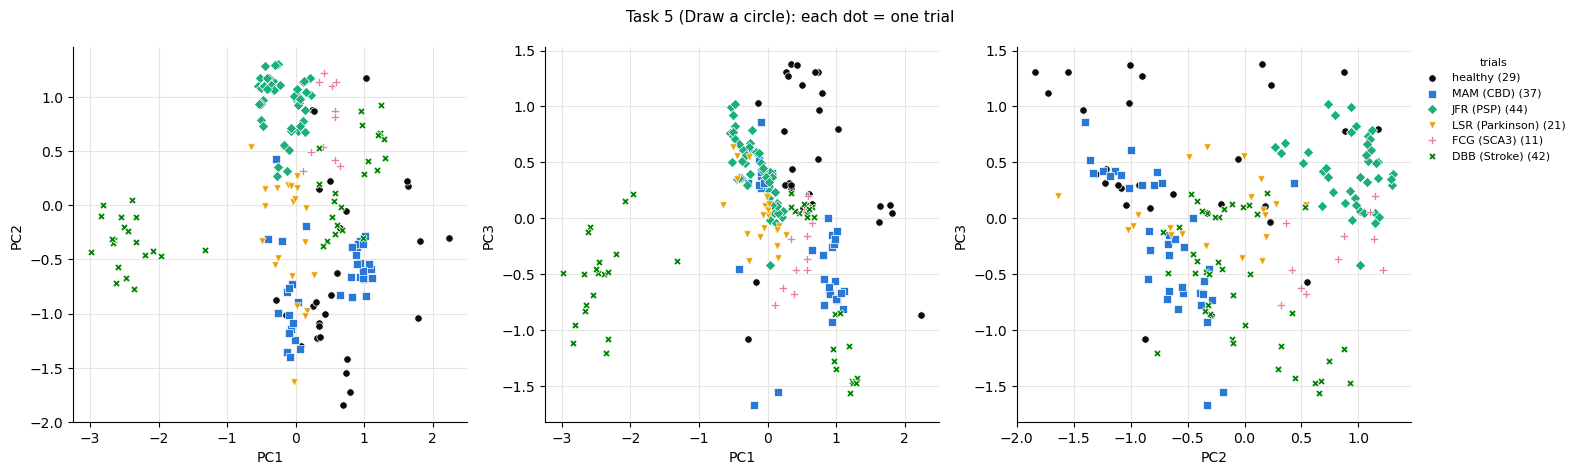

{'task_id': 5,
 'trials': 184,
 'persons': 9,
 'PC1_%': np.float64(32.2),
 'PC2_%': np.float64(19.9),
 'PC3_%': np.float64(13.2),
 'PC1-3_total_%': np.float64(65.3)}

In [44]:
pca.run_task(shape_table, 5, STYLES, N_KEEP, N_PCS_SHOWN, UNIT)

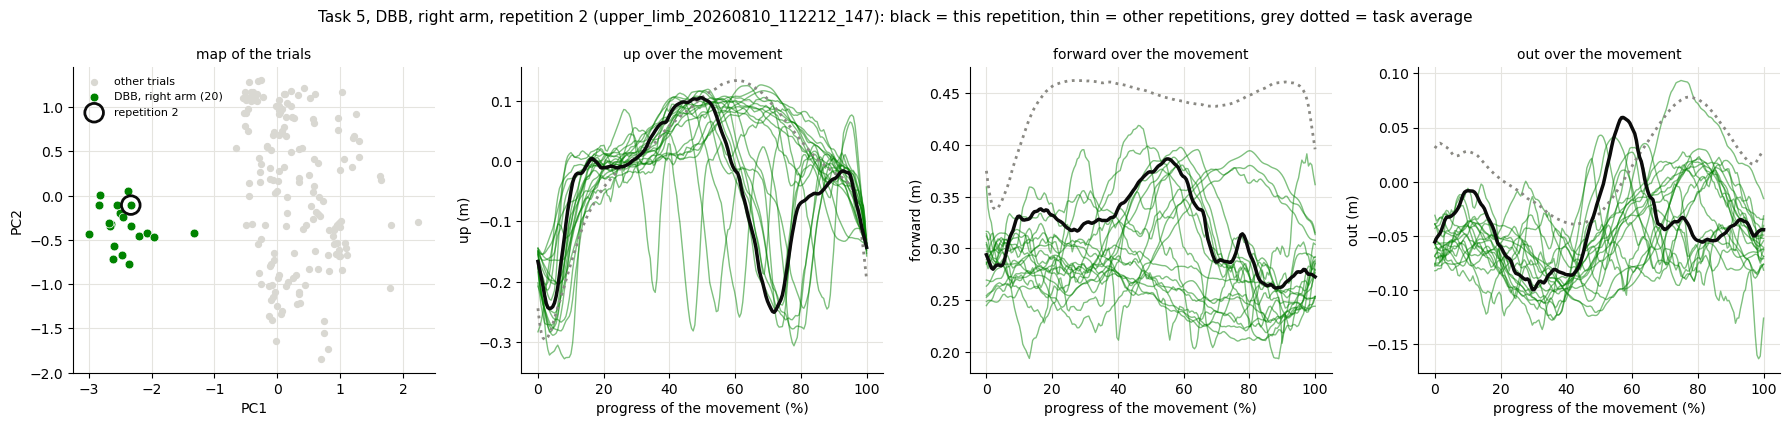

     this repetition  DBB median  DBB spread (std)  all trials spread (std)
PC1            -2.33       -2.49              0.36                     1.01
PC2            -0.11       -0.34              0.23                     0.80
PC3            -1.08       -0.49              0.39                     0.65


In [45]:
pca.inspect_trial(shape_table, 5, person="DBB", side="right", repetition=2, styles=STYLES, pcs=("PC1", "PC2"), unit=UNIT)

## Task 6: Horizontal reaching

Task 6 (Horizontal reaching): 682 trials from 16 persons (CBD: 1, PSP: 1, Parkinson: 1, SCA3: 1, Stroke: 2, healthy: 10), 200 points x 3 directions x 1 point(s) (wrist)


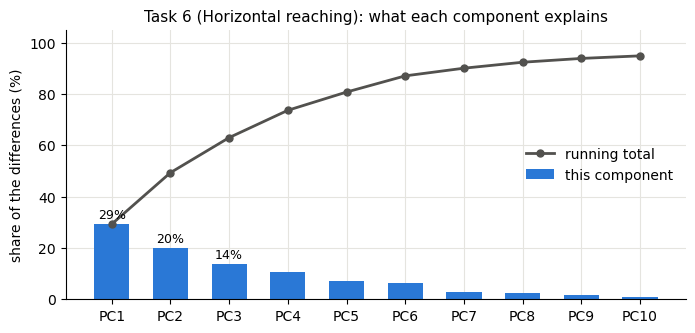

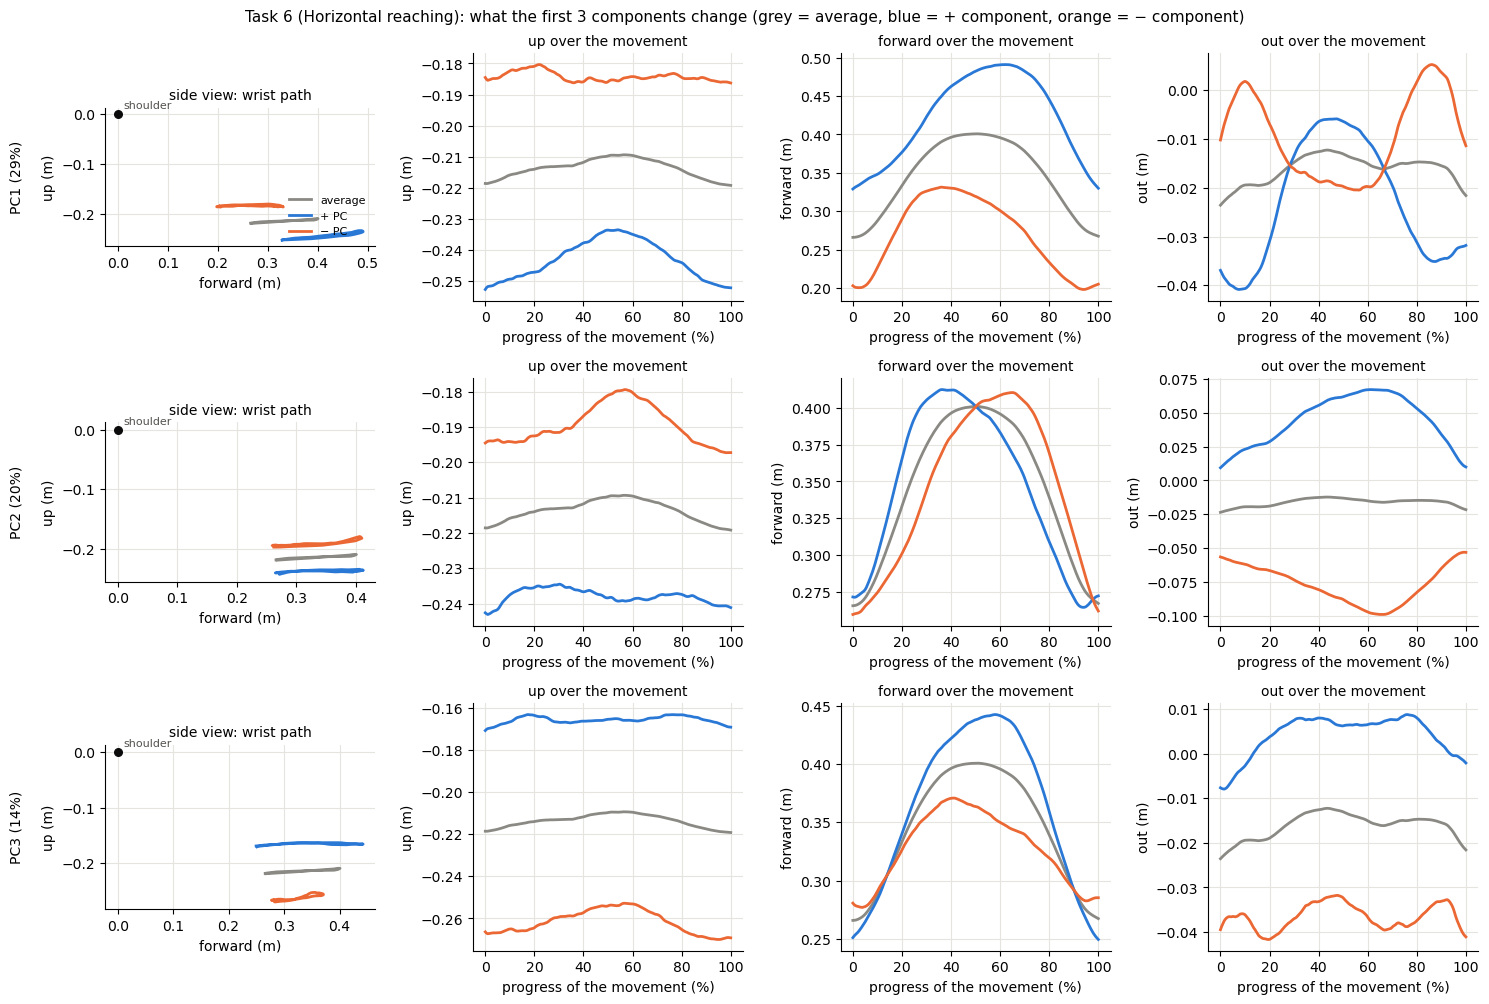

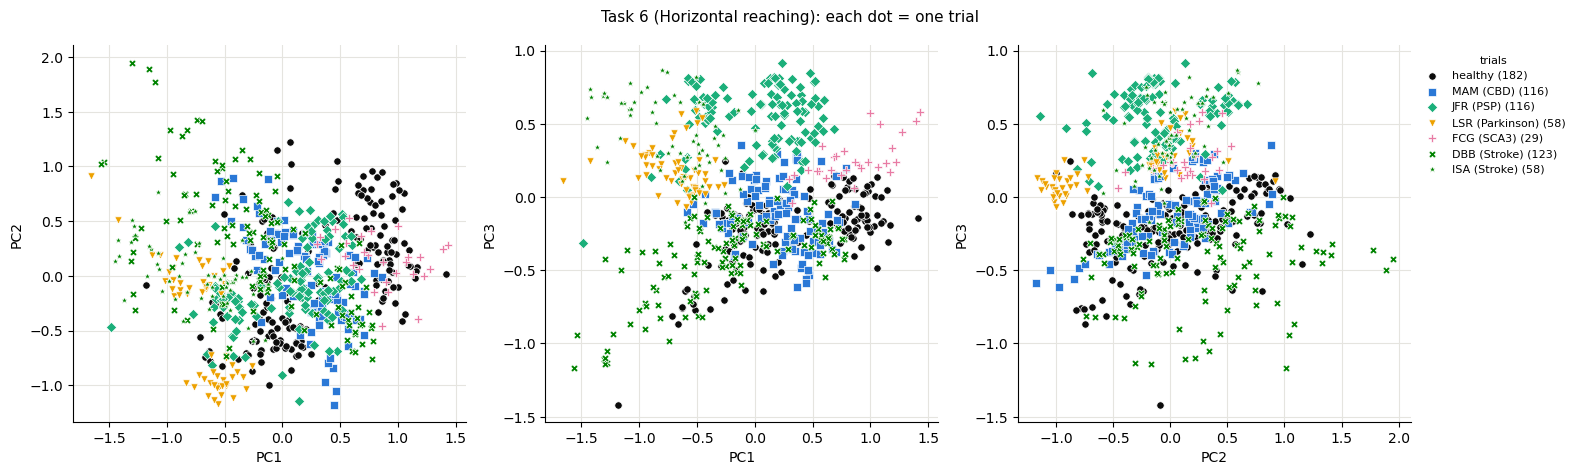

{'task_id': 6,
 'trials': 682,
 'persons': 16,
 'PC1_%': np.float64(29.3),
 'PC2_%': np.float64(20.1),
 'PC3_%': np.float64(13.7),
 'PC1-3_total_%': np.float64(63.0)}

In [46]:
pca.run_task(shape_table, 6, STYLES, N_KEEP, N_PCS_SHOWN, UNIT)

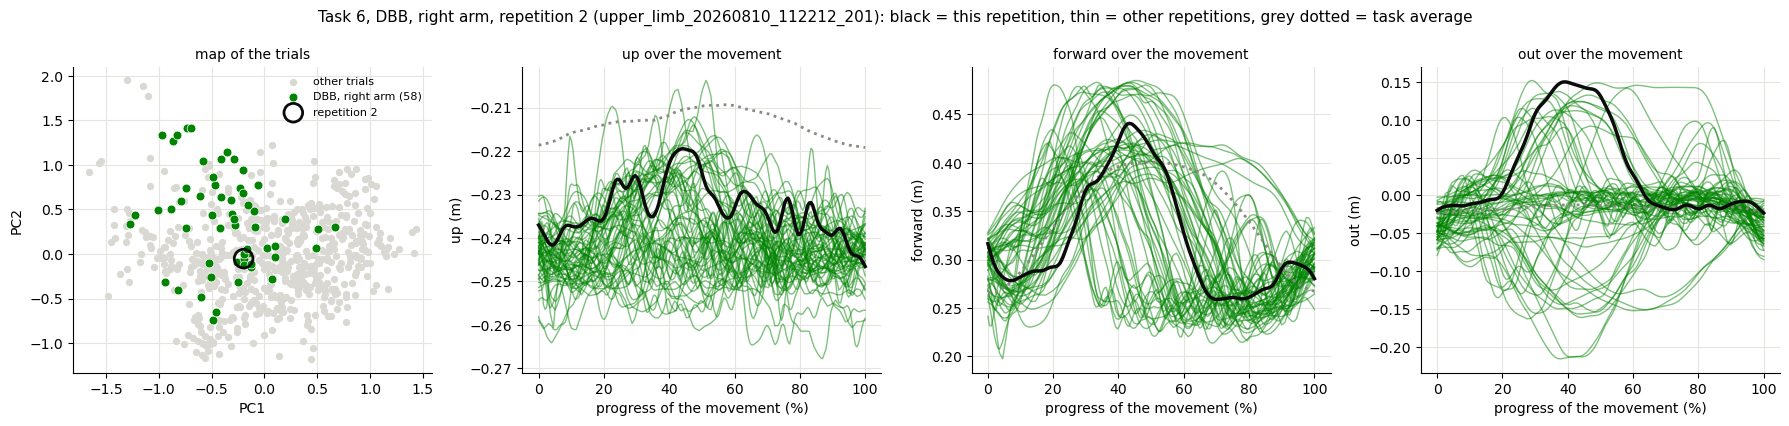

     this repetition  DBB median  DBB spread (std)  all trials spread (std)
PC1            -0.20       -0.33              0.40                     0.60
PC2            -0.05        0.37              0.54                     0.50
PC3            -0.29       -0.39              0.26                     0.41


In [47]:
pca.inspect_trial(shape_table, 6, person="DBB", side="right", repetition=2, styles=STYLES, pcs=("PC1", "PC2"), unit=UNIT)

## Task 7: Drinking test: reaching glass to mouth

Task 7 (Drinking test: reaching glass to mouth): 226 trials from 9 persons (CBD: 1, MSA-C: 1, PSP: 1, Parkinson: 1, SCA3: 1, Stroke: 2, healthy: 2), 200 points x 3 directions x 1 point(s) (wrist)


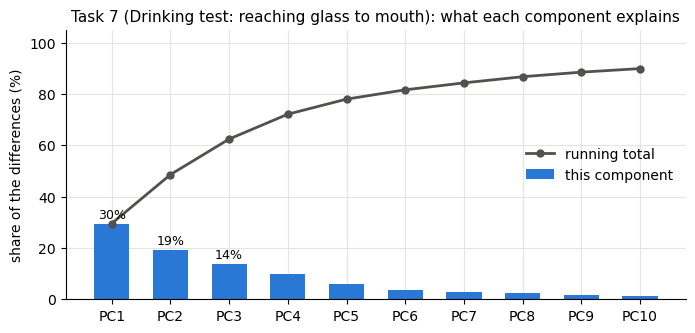

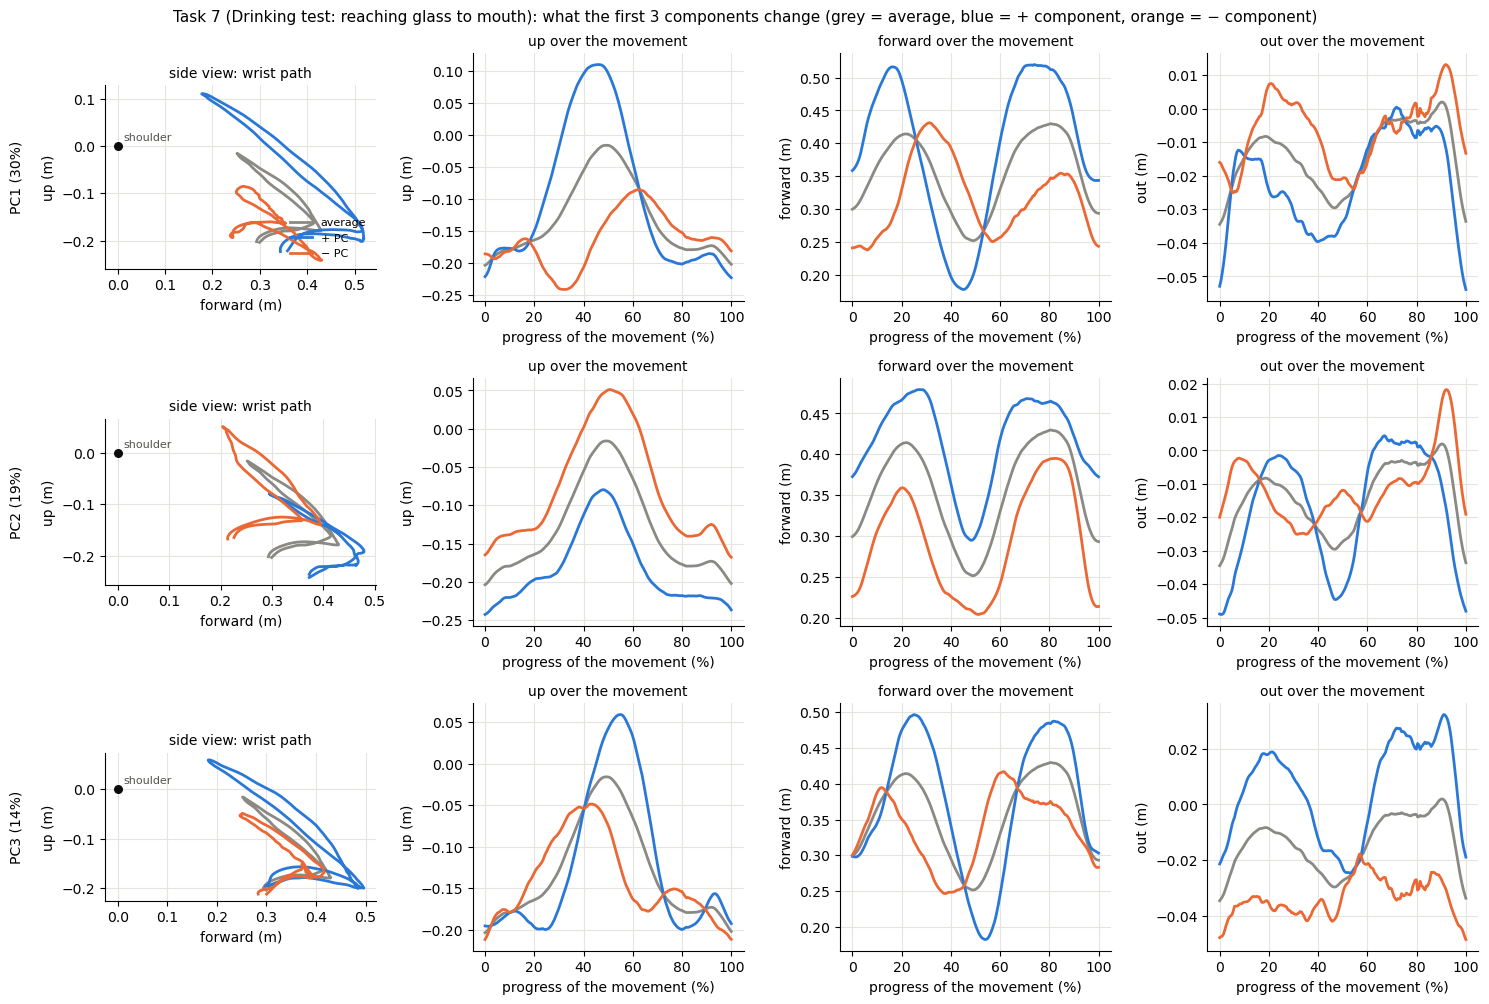

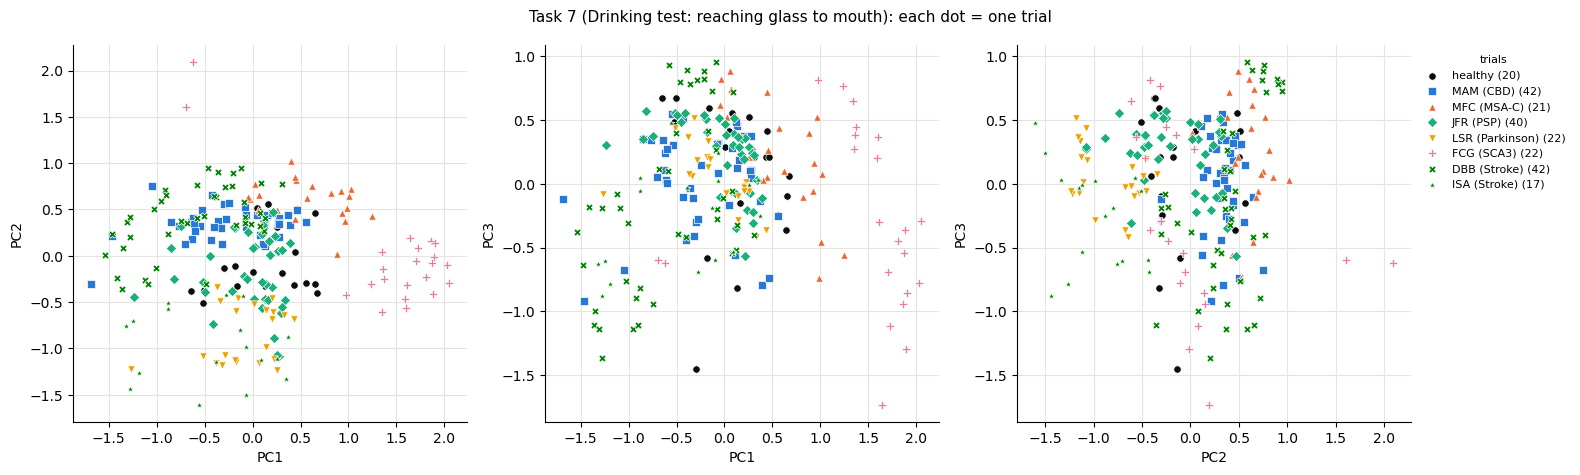

{'task_id': 7,
 'trials': 226,
 'persons': 9,
 'PC1_%': np.float64(29.5),
 'PC2_%': np.float64(19.1),
 'PC3_%': np.float64(13.9),
 'PC1-3_total_%': np.float64(62.4)}

In [48]:
pca.run_task(shape_table, 7, STYLES, N_KEEP, N_PCS_SHOWN, UNIT)

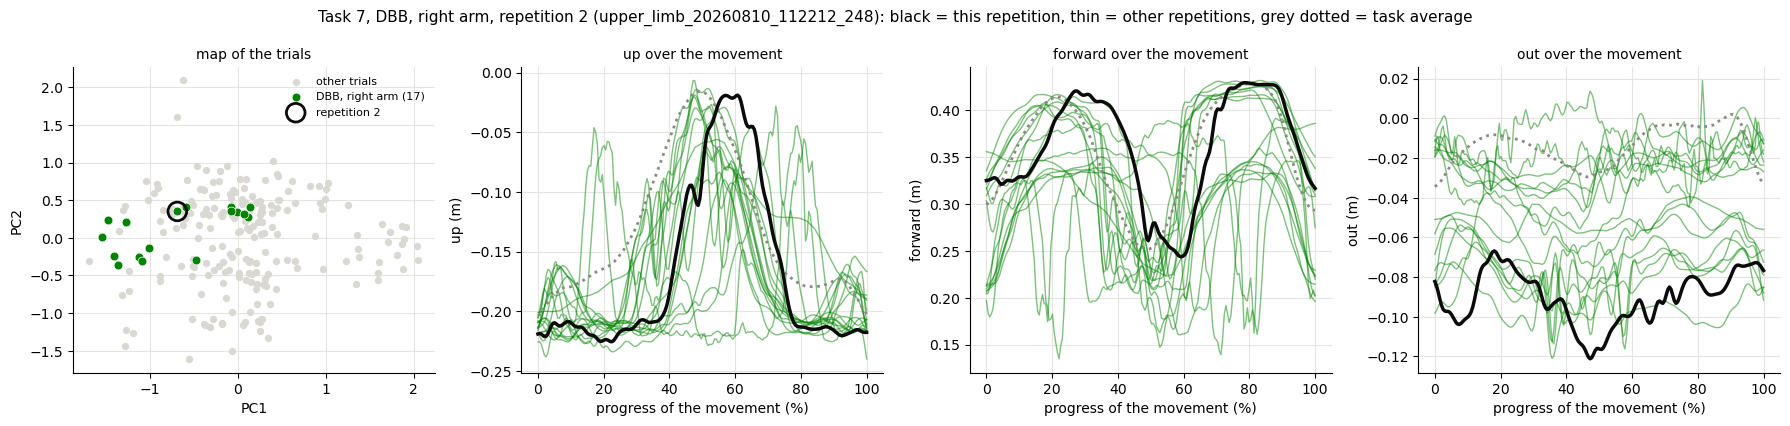

     this repetition  DBB median  DBB spread (std)  all trials spread (std)
PC1            -0.69       -0.69              0.63                     0.75
PC2             0.35        0.24              0.30                     0.60
PC3             0.12       -0.31              0.39                     0.51


In [49]:
pca.inspect_trial(shape_table, 7, person="DBB", side="right", repetition=2, styles=STYLES, pcs=("PC1", "PC2"), unit=UNIT)

## Task 8: Index to nose

Task 8 (Index to nose): 218 trials from 8 persons (CBD: 1, MSA-C: 1, PSP: 1, Parkinson: 1, Stroke: 2, healthy: 2), 200 points x 3 directions x 1 point(s) (wrist)


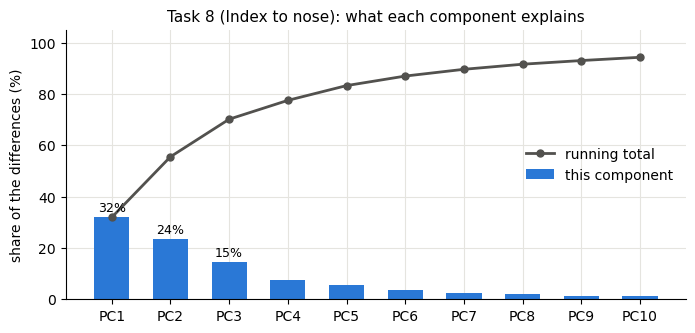

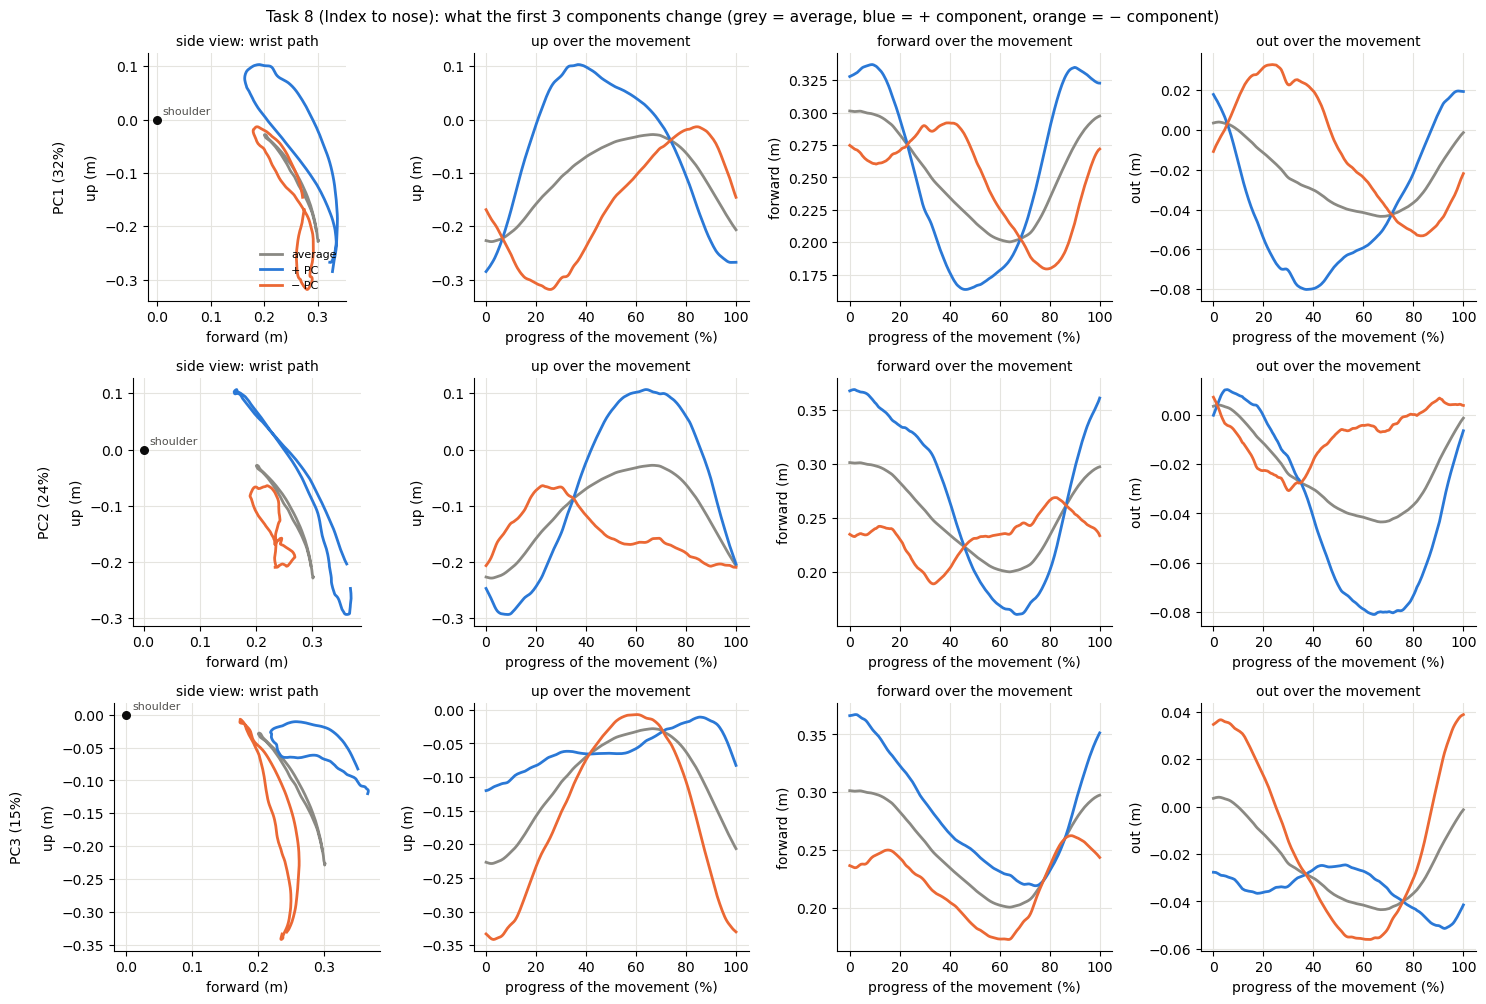

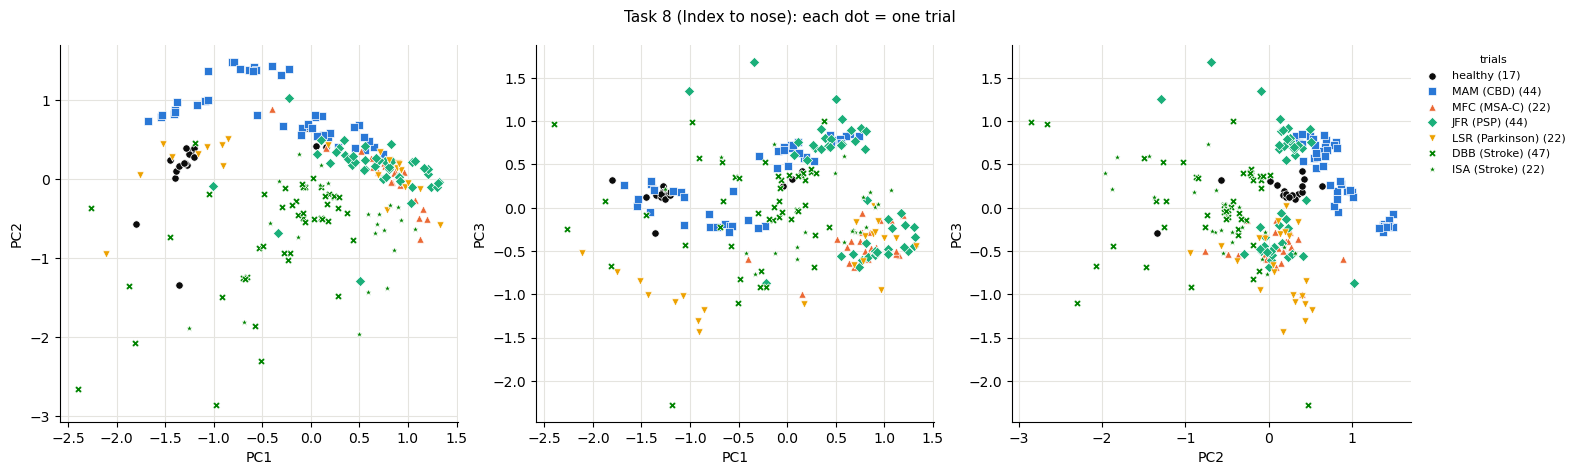

{'task_id': 8,
 'trials': 218,
 'persons': 8,
 'PC1_%': np.float64(31.9),
 'PC2_%': np.float64(23.6),
 'PC3_%': np.float64(14.6),
 'PC1-3_total_%': np.float64(70.2)}

In [50]:
pca.run_task(shape_table, 8, STYLES, N_KEEP, N_PCS_SHOWN, UNIT)

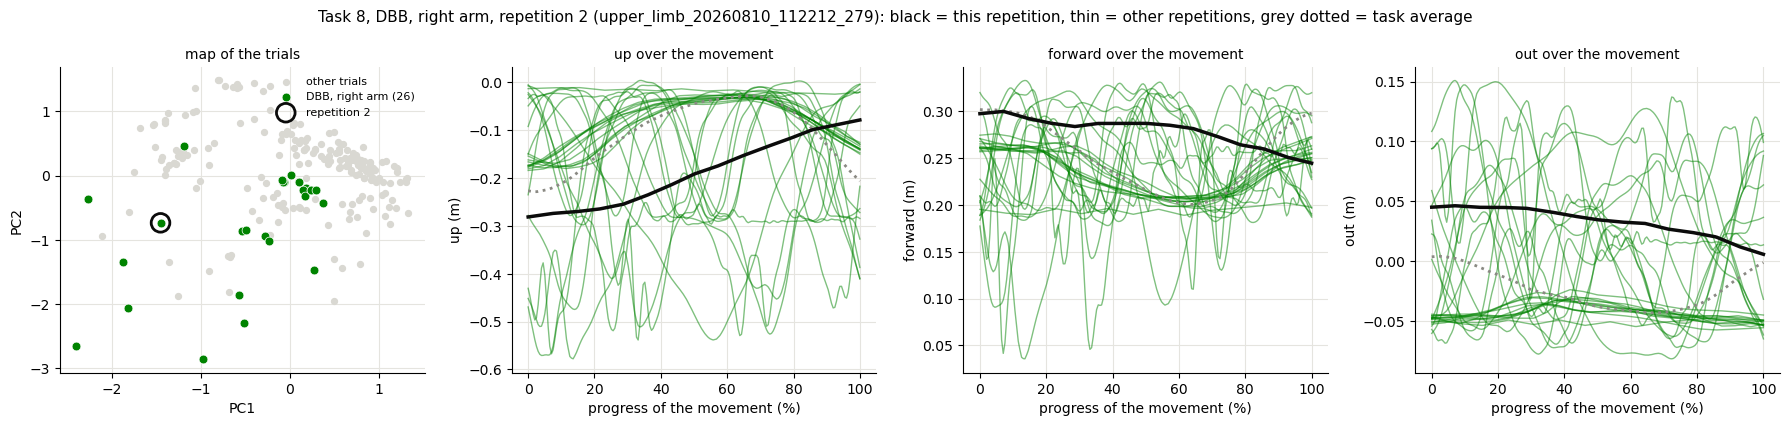

     this repetition  DBB median  DBB spread (std)  all trials spread (std)
PC1            -1.45       -0.16              0.84                     0.86
PC2            -0.74       -0.40              0.90                     0.74
PC3            -0.08        0.35              0.73                     0.59


In [51]:
pca.inspect_trial(shape_table, 8, person="DBB", side="right", repetition=2, styles=STYLES, pcs=("PC1", "PC2"), unit=UNIT)

## Summary across tasks
How much the first 3 components explain in each task. A high total = the movements of that task differ in only a few ways.

In [52]:
pca.summary_all_tasks(shape_table)

,trials,persons,PC1_%,PC2_%,PC3_%,PC1-3_total_%
task_id,,,,,,
1,276,13,49.1,13.2,12.3,74.6
2,248,10,39.3,19.5,13.3,72.0
3,186,9,23.4,19.4,8.5,51.3
4,505,8,43.2,17.9,13.4,74.5
5,184,9,32.2,19.9,13.2,65.3
6,682,16,29.3,20.1,13.7,63.0
7,226,9,29.5,19.1,13.9,62.4
8,218,8,31.9,23.6,14.6,70.2


## Comparison with the old PCA

The old table (`shape_tables.parquet` of the old repo) kept only the way out for tasks 1, 2, 4, 6, 7, 8. To compare all 8 tasks, the new table is rebuilt here with **`SHAPE_PART = "way_out"`** (wrist only, in metres, like the old one), whatever the settings above. Same trial selection.

They will not be identical: the movement is now cut by speed (step 3) and filtered (step 2), and the way out ends at the goal event (old: at the furthest point). But they should be close.

In [53]:
way_out_table = shapes.build_shape_table(movement_cut, selected, {**settings, "shape_part": "way_out",
                                                                  "points": ["wrist"], "scale_by_arm_length": False})
old_table = pd.read_parquet(OLD_PROCESSED_ROOT / "shape_tables.parquet").rename(columns={"patient_id": "person"})

comparison = pca.summary_all_tasks(old_table).join(pca.summary_all_tasks(way_out_table), lsuffix=" old", rsuffix=" new")
comparison[[f"{column} {version}" for column in ["trials", "PC1_%", "PC2_%", "PC3_%", "PC1-3_total_%"]
            for version in ["old", "new"]]]

,trials old,trials new,PC1_% old,PC1_% new,PC2_% old,PC2_% new,PC3_% old,PC3_% new,PC1-3_total_% old,PC1-3_total_% new
task_id,,,,,,,,,,
1,277,276,57.7,38.7,18.5,17.1,7.6,13.6,83.8,69.4
2,248,248,44.8,35.8,22.0,18.0,13.3,16.4,80.1,70.2
3,187,186,23.8,26.8,19.8,21.3,9.9,9.7,53.5,57.8
4,505,505,37.9,47.5,31.5,19.6,11.7,13.3,81.1,80.4
5,184,184,33.5,32.4,21.8,21.6,11.5,12.7,66.7,66.7
6,682,682,39.8,42.0,25.3,23.6,20.3,19.6,85.4,85.3
7,226,225,49.4,40.9,22.9,25.4,9.2,13.5,81.5,79.8
8,218,205,44.4,52.8,30.5,30.3,12.2,7.2,87.1,90.3


## Save
Writes `shape_tables.parquet` (one row per trial, all tasks), `pca_scores.parquet` (PC1 ... PC`N_KEEP` per trial, with `trial_id` and `task_id`) and `shapes_settings.json` (the settings above) to `data/processed/`. Running it again overwrites them.

In [54]:
shapes.save_shape_table(shape_table, settings)
pca.save_scores(pca.all_scores(shape_table, N_KEEP))

shape_tables.parquet        14.8 MB
shapes_settings.json         0.0 MB
pca_scores.parquet       2,525 trials x 12 columns
